In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3

In [7]:
## load map database
path_to_db = '/mnt/d/data/magnification_maps/masterlist.db'
db = sqlite3.connect(path_to_db)
## select maps
df = pd.read_sql_query("SELECT * FROM maps WHERE 1/((1-kappa)*(1-kappa) - gamma*gamma) > 0 AND kappa < 1.0 AND kappa > 0.0", db)

In [8]:
print(df.to_string())

       index     id  kappa  gamma     s
0          0  37836   0.52   0.32  0.80
1          5  87150   0.52   0.30  0.95
2          6  79782   0.38   0.49  0.80
3          8  85664   0.50   0.27  0.50
4          9  65905   0.32   0.56  0.99
5         11  21402   0.57   0.38  0.30
6         14   5366   0.65   0.30  0.00
7         15  40921   0.33   0.55  0.00
8         18  23336   0.30   0.49  0.10
9         19  89045   0.05   0.88  0.10
10        20  73531   0.50   0.46  0.40
11        23  52727   0.89   0.03  0.10
12        24  83362   0.16   0.67  0.00
13        25  29011   0.63   0.33  0.10
14        27  79616   0.39   0.48  0.20
15        28  81456   0.73   0.01  0.10
16        30   7808   0.45   0.50  0.30
17        32  65891   0.31   0.58  0.70
18        33  21596   0.38   0.48  0.10
19        34  75037   0.28   0.23  0.70
20        37  12986   0.72   0.18  0.00
21        39  81998   0.14   0.47  0.10
22        41  65528   0.27   0.53  0.70
23        42  75040   0.28   0.26  0.70


In [9]:
mapid = 14733#13717

## load Luke's mpds
mask = df['id']==mapid
kappa = df[mask]['kappa'].values[0]
gamma = df[mask]['gamma'].values[0]
s = df[mask]['s'].values[0]

mu_macro = 1 / ((1 - kappa)**2 - gamma**2)

filename = 'k_' + str(kappa) + '_y_' + str(gamma) + '_s_' + str(s) + '.npy'
print(filename)

#log_mu, p_log_mu = np.load('/home/favio/software/notebooks/imf_with_doubles/bayesian_microlensing/data/histograms/k_0.38_y_0.38_s_0.96.npy').T
log_mu, p_log_mu = np.load('/home/favio/software/notebooks/imf_with_doubles/bayesian_microlensing/data/histograms/' + filename).T
## normalize p
p_log_mu = p_log_mu / np.sum(p_log_mu)
## normalize to mu_macro
log_mu = log_mu  - np.log10(mu_macro)

k_0.06_y_0.2_s_0.0.npy


FileNotFoundError: [Errno 2] No such file or directory: '/home/favio/software/notebooks/imf_with_doubles/bayesian_microlensing/data/histograms/k_0.06_y_0.2_s_0.0.npy'

In [11]:
## load gerlumph mpds
mu, p_mu = np.loadtxt('/mnt/d/data/imf_with_doubles/test/' + str(mapid) +'.dat').T
log10_mu = np.log10(mu)

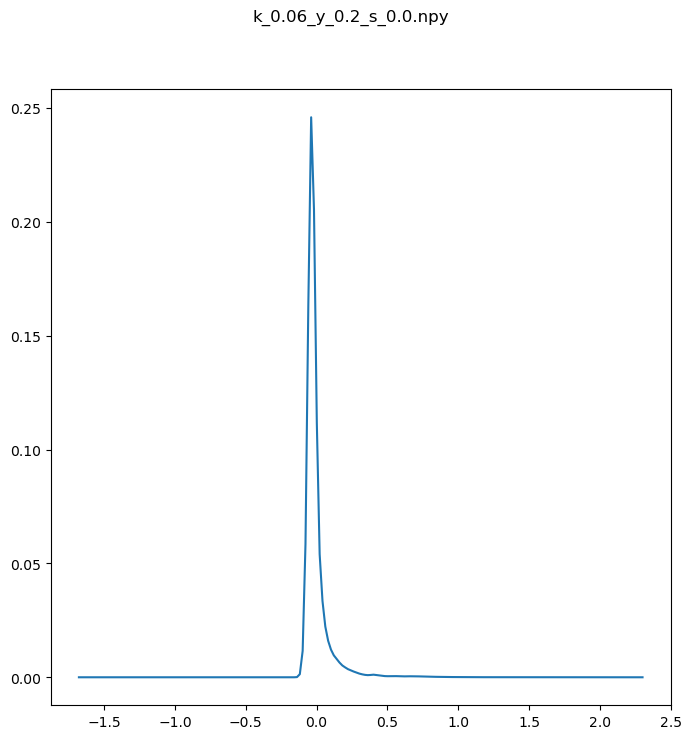

In [12]:
fig, ax = plt.subplots(1, 1, figsize=(8, 8))

fig.suptitle(filename)

ax.plot(log10_mu, p_mu)

#ax.plot(log_mu, p_log_mu);

In [8]:
np.sum(p_log_mu)

49.99999999999995